<a href="https://colab.research.google.com/github/Hunterashcraft04/SemanticsOfDataViz_HAshcraftGTUgThesis/blob/main/DataVizThesis_StimGen/RSA/DataVizStim_RSAValidation(RDM%2BPCA).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# import dependencies
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import re
import os
import torch
import zipfile
import shutil
from pathlib import Path
from PIL import Image
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from google.colab import files
from scipy.stats import spearmanr
from matplotlib.lines import Line2D


In [2]:
# upload one ZIP containing the generated stimulus images
# filenames are used as the metadata source; no Excel manifest is required
uploaded = files.upload()

if len(uploaded) != 1:
    raise Exception("Upload exactly one .zip file containing the stimulus images.")

upload_name = list(uploaded.keys())[0]
if not upload_name.lower().endswith('.zip'):
    raise Exception("The uploaded file must be a .zip archive containing the stimulus images.")

# clean extraction directory so an old run cannot contaminate a new analysis
iDir = "stimulus_images"
if os.path.exists(iDir):
    shutil.rmtree(iDir)
os.makedirs(iDir, exist_ok=True)

with zipfile.ZipFile(upload_name, 'r') as zip_ref:
    zip_ref.extractall(iDir)

# recursively find images, so the ZIP may contain any folder structure
image_paths = sorted([
    str(p) for p in Path(iDir).rglob('*')
    if p.suffix.lower() in {'.png', '.jpg', '.jpeg'}
])

if len(image_paths) == 0:
    raise Exception("No PNG/JPG/JPEG stimulus images were found in the uploaded ZIP.")

print(f"Successfully uploaded: {upload_name}")
print(f"Found {len(image_paths)} stimulus images.")


Saving dataVizSetPilot_0.zip to dataVizSetPilot_0.zip
Successfully uploaded: dataVizSetPilot_0.zip
Found 72 stimulus images.


In [3]:
# parse stimulus metadata directly from each filename
# supported correlation tags include the current generator names plus simpler aliases
CORR_LABEL_MAP = {
    'negSrngCor': 'strongNeg',
    'strongNeg': 'strongNeg',
    'negCor': 'neg',
    'neg': 'neg',
    'posCor': 'pos',
    'pos': 'pos',
    'posSrngCor': 'strongPos',
    'strongPos': 'strongPos',
    'noCor': 'noCor'
}

CORR_ORDER = ['strongNeg', 'neg', 'noCor', 'pos', 'strongPos']


def parse_stimulus_filename(path):
    fn = os.path.basename(path)

    # figure number: scatter_plot12...
    stim_match = re.search(r'scatter[_-]?plot(\d+)', fn, flags=re.IGNORECASE)
    stim_num = int(stim_match.group(1)) if stim_match else None

    # numeric r value: (r=-0.742)
    r_match = re.search(r'r=([-+]?\d*\.?\d+)', fn, flags=re.IGNORECASE)
    r_value = float(r_match.group(1)) if r_match else None

    # correlation category tag
    corr_tag = None
    for raw_tag in ['negSrngCor', 'strongNeg', 'negCor', 'neg', 'posSrngCor', 'strongPos', 'posCor', 'pos', 'noCor']:
        if re.search(rf'(?<![A-Za-z]){re.escape(raw_tag)}(?![A-Za-z])', fn, flags=re.IGNORECASE):
            # recover canonical key without relying on input capitalization
            key = next(k for k in CORR_LABEL_MAP if k.lower() == raw_tag.lower())
            corr_tag = CORR_LABEL_MAP[key]
            break

    # if the text tag is absent but r exists, derive the category from r
    if corr_tag is None and r_value is not None:
        if r_value <= -0.7:
            corr_tag = 'strongNeg'
        elif r_value < 0:
            corr_tag = 'neg'
        elif r_value == 0:
            corr_tag = 'noCor'
        elif r_value < 0.7:
            corr_tag = 'pos'
        else:
            corr_tag = 'strongPos'

    # outlier tag: filenames with _out(...) are outlier trials
    has_outlier = bool(re.search(r'_out(?:\(|_|\.|$)', fn, flags=re.IGNORECASE))

    md_match = re.search(r'MD=([-+]?\d*\.?\d+)', fn, flags=re.IGNORECASE)
    z_match = re.search(r'z=([-+]?\d*\.?\d+)', fn, flags=re.IGNORECASE)
    md_value = float(md_match.group(1)) if md_match else np.nan
    z_value = float(z_match.group(1)) if z_match else np.nan

    # ink-on-page density tag
    if re.search(r'(?:^|_)high(?:\.|_|$)', fn, flags=re.IGNORECASE):
        ink_density = 'high'
    elif re.search(r'(?:^|_)low(?:\.|_|$)', fn, flags=re.IGNORECASE):
        ink_density = 'low'
    else:
        ink_density = 'unknown'

    return {
        'stim_fns': fn,
        'image_path': path,
        'stim_num': stim_num,
        'r': r_value,
        'corr_class': corr_tag,
        'outlier': has_outlier,
        'MD': md_value,
        'z': z_value,
        'ink_density': ink_density
    }


df = pd.DataFrame([parse_stimulus_filename(p) for p in image_paths])

# validation: RSA ground truth requires an r value for every stimulus
missing_r = df[df['r'].isna()]
if len(missing_r) > 0:
    raise Exception(
        "Could not parse an r value from these filenames:\n" +
        "\n".join(missing_r['stim_fns'].tolist())
    )

# stable, reproducible initial order
if df['stim_num'].notna().all():
    df = df.sort_values('stim_num').reset_index(drop=True)
else:
    df = df.sort_values('stim_fns').reset_index(drop=True)

print("Parsed stimulus metadata:")
display(df[['stim_fns', 'stim_num', 'r', 'corr_class', 'outlier', 'ink_density', 'MD', 'z']])
print("\nCounts by condition:")
display(df.groupby(['corr_class', 'outlier', 'ink_density'], dropna=False).size().rename('n').reset_index())


Parsed stimulus metadata:


,stim_fns,stim_num,r,corr_class,outlier,ink_density,MD,z
0,scatter_plot1_posSrngCor(r=0.955)_out(MD=3.406...,1,0.955,strongPos,True,unknown,3.406,4.375
1,scatter_plot2_posSrngCor(r=0.970)_out(MD=4.924...,2,0.970,strongPos,True,unknown,4.924,5.379
2,scatter_plot3_posSrngCor(r=0.937).png,3,0.937,strongPos,False,unknown,NaN,NaN
3,scatter_plot4_posSrngCor(r=0.908)_out(MD=4.788...,4,0.908,strongPos,True,unknown,4.788,5.495
4,scatter_plot5_posSrngCor(r=0.879)_out(MD=4.432...,5,0.879,strongPos,True,unknown,4.432,4.984
...,...,...,...,...,...,...,...,...
67,scatter_plot68_negSrngCor(r=-0.870).png,68,-0.870,strongNeg,False,unknown,NaN,NaN
68,scatter_plot69_negSrngCor(r=-0.907).png,69,-0.907,strongNeg,False,unknown,NaN,NaN
69,scatter_plot70_negSrngCor(r=-0.941).png,70,-0.941,strongNeg,False,unknown,NaN,NaN
70,scatter_plot71_negSrngCor(r=-0.957).png,71,-0.957,strongNeg,False,unknown,NaN,NaN



Counts by condition:


,corr_class,outlier,ink_density,n
0,neg,False,unknown,10
1,neg,True,unknown,16
2,pos,False,unknown,15
3,pos,True,unknown,10
4,strongNeg,False,unknown,6
5,strongNeg,True,unknown,4
6,strongPos,False,unknown,5
7,strongPos,True,unknown,6


In [4]:
# install CLIP from the OpenAI GitHub
!pip install ftfy regex tqdm -q
!pip install git+https://github.com/openai/CLIP.git -q

import clip


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [5]:
# load CLIP
# CUDA will be used automatically when available
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Running on device: {device}")

model, preprocess = clip.load("ViT-B/32", device=device)


Running on device: cpu


100%|███████████████████████████████████████| 338M/338M [00:18<00:00, 19.2MiB/s]


In [6]:
# CLIP embeddings for the full uploaded set
# Embeddings are computed once, then reused for each subset analysis.
CLIP_embeddings_all = []
print('Passing all DataViz stimuli through CLIP...')

for row in df.itertuples(index=False):
    img = Image.open(row.image_path).convert("RGB")
    img_input = preprocess(img).unsqueeze(0).to(device)

    with torch.no_grad():
        img_feat = model.encode_image(img_input)
        feat = img_feat.cpu().numpy().flatten()
        CLIP_embeddings_all.append(feat)

CLIP_embeddings_all = np.asarray(CLIP_embeddings_all)
print(f"Computed CLIP embeddings for {len(CLIP_embeddings_all)} stimuli.")


Passing all DataViz stimuli through CLIP...
Computed CLIP embeddings for 72 stimuli.


In [7]:
# functions for subset-level RDM / RSA / PCA analyses

def category_spans(labels):
    spans = []
    if len(labels) == 0:
        return spans
    start = 0
    for i in range(1, len(labels) + 1):
        if i == len(labels) or labels[i] != labels[start]:
            spans.append((start, i, labels[start]))
            start = i
    return spans


def prepare_sorted_subset(sub_df, embeddings_sub):
    # 1. ground-truth RDM from the true r values
    r = sub_df['r'].to_numpy(dtype=float)
    ground_truth_RDM = np.abs(r[:, None] - r[None, :])

    # 2. CLIP RDM from the subset embeddings
    CLIP_RDM = 1 - cosine_similarity(embeddings_sub)

    # 3. shared sorting for BOTH RDMs
    sort_df = sub_df.assign(
        corr_order=pd.Categorical(sub_df['corr_class'], categories=CORR_ORDER, ordered=True),
        ink_order=pd.Categorical(sub_df['ink_density'], categories=['low', 'high', 'unknown'], ordered=True)
    )
    ind_sort = sort_df.sort_values(
        ['r', 'corr_order', 'outlier', 'ink_order', 'stim_num'],
        na_position='last'
    ).index.to_numpy()

    plot_df = sub_df.iloc[ind_sort].reset_index(drop=True)
    RDM_GT = ground_truth_RDM[ind_sort][:, ind_sort]
    RDM_CLIP = CLIP_RDM[ind_sort][:, ind_sort]
    corr_spans = category_spans(plot_df['corr_class'].fillna('unknown').tolist())

    return plot_df, RDM_GT, RDM_CLIP, corr_spans


def compute_rsa(RDM_GT, RDM_CLIP):
    if RDM_GT.shape[0] < 3:
        return np.nan, np.nan

    upper_tri_inds = np.triu_indices(RDM_GT.shape[0], k=1)
    gt_flat = RDM_GT[upper_tri_inds]
    clip_flat = RDM_CLIP[upper_tri_inds]
    rho, p = spearmanr(gt_flat, clip_flat)
    return rho, p


def compute_pca_features(RDM_CLIP):
    n_stim = RDM_CLIP.shape[0]
    if n_stim < 2:
        return None, np.nan, np.nan, np.nan

    pca = PCA(n_components=2)
    pca_features = pca.fit_transform(RDM_CLIP)
    pc1_var = pca.explained_variance_ratio_[0] * 100
    pc2_var = pca.explained_variance_ratio_[1] * 100
    total_var = pc1_var + pc2_var
    return pca_features, pc1_var, pc2_var, total_var


def draw_rdm(ax, matrix, title, cbar_label, corr_spans, n_items):
    hm = sns.heatmap(
        matrix,
        ax=ax,
        cmap="rocket_r",
        square=True,
        rasterized=True,
        xticklabels=False,
        yticklabels=False,
        cbar_kws={'label': cbar_label, 'shrink': 0.80}
    )
    ax.invert_yaxis()
    ax.set_title(title, weight='bold', pad=12)

    for start, end, label in corr_spans:
        ax.vlines([start, end], 0, n_items, colors='black', linewidth=1.5)
        ax.hlines([start, end], 0, n_items, colors='black', linewidth=1.5)
        center = (start + end) / 2
        ax.text(center, -1.5, label, ha='center', va='top', weight='bold', rotation=90, fontsize=8)
        ax.text(-1.5, center, label, ha='right', va='center', weight='bold', fontsize=8)

    cbar = hm.collections[0].colorbar
    cbar.ax.set_ylabel(cbar_label, weight='bold', rotation=-90, va='bottom')


def make_combined_figure(plot_df, RDM_GT, RDM_CLIP, corr_spans, rho, p, pca_features, pc1_var, pc2_var, total_var, analysis_title, output_fn):
    fig = plt.figure(figsize=(18, 16))
    gs = fig.add_gridspec(
        2, 4,
        height_ratios=[1.05, 0.90],
        hspace=0.35,
        wspace=0.45
    )

    ax_gt = fig.add_subplot(gs[0, 0:2])
    ax_clip = fig.add_subplot(gs[0, 2:4])
    ax_pca = fig.add_subplot(gs[1, 1:3])

    draw_rdm(
        ax_gt,
        RDM_GT,
        "Ground-Truth RDM",
        "Dissimilarity |rᵢ - rⱼ|",
        corr_spans,
        len(plot_df)
    )

    draw_rdm(
        ax_clip,
        RDM_CLIP,
        "CLIP RDM",
        "Dissimilarity (1 - cosine similarity)",
        corr_spans,
        len(plot_df)
    )

    marker_map = {
        ('low', False): 'o',
        ('low', True): '^',
        ('high', False): 's',
        ('high', True): 'D',
        ('unknown', False): 'P',
        ('unknown', True): 'X'
    }

    r_sorted = plot_df['r'].to_numpy(dtype=float)

    if pca_features is not None:
        for condition, marker in marker_map.items():
            ink, outlier = condition
            mask = (
                (plot_df['ink_density'].to_numpy() == ink) &
                (plot_df['outlier'].to_numpy() == outlier)
            )
            if np.any(mask):
                ax_pca.scatter(
                    pca_features[mask, 0],
                    pca_features[mask, 1],
                    c=r_sorted[mask],
                    cmap='rocket',
                    vmin=np.nanmin(r_sorted),
                    vmax=np.nanmax(r_sorted),
                    marker=marker,
                    s=70,
                    alpha=0.9,
                    edgecolors='black',
                    linewidths=0.5
                )

        sm = plt.cm.ScalarMappable(
            cmap='rocket',
            norm=plt.Normalize(vmin=np.nanmin(r_sorted), vmax=np.nanmax(r_sorted))
        )
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax_pca, pad=0.02)
        cbar.set_label('Ground-truth correlation (r)', weight='bold')

        legend_handles = []
        for (ink, outlier), marker in marker_map.items():
            exists = np.any(
                (plot_df['ink_density'].to_numpy() == ink) &
                (plot_df['outlier'].to_numpy() == outlier)
            )
            if exists:
                out_text = 'outlier' if outlier else 'no outlier'
                legend_handles.append(
                    Line2D(
                        [0], [0], marker=marker, linestyle='None',
                        markerfacecolor='lightgray', markeredgecolor='black',
                        markersize=8, label=f'{ink} ink / {out_text}'
                    )
                )

        if legend_handles:
            ax_pca.legend(handles=legend_handles, title='Filename conditions', loc='best', frameon=True)

        ax_pca.set_title(
            f"PCA of CLIP RDM\nPC1 + PC2 = {total_var:.2f}% variance",
            weight='bold'
        )
        ax_pca.set_xlabel(f"PC1 ({pc1_var:.2f}% Var)", weight='bold')
        ax_pca.set_ylabel(f"PC2 ({pc2_var:.2f}% Var)", weight='bold')
        ax_pca.grid(True, linestyle='--', alpha=0.35)
    else:
        ax_pca.axis('off')
        ax_pca.text(
            0.5, 0.5,
            'PCA unavailable: fewer than 2 stimuli in this subset.',
            ha='center', va='center', fontsize=13, weight='bold'
        )

    rho_text = 'nan' if pd.isna(rho) else f'{rho:.3f}'
    p_text = 'nan' if pd.isna(p) else f'{p:.3e}'
    fig.suptitle(
        f"{analysis_title}  |  Spearman ρ = {rho_text}, p = {p_text}",
        fontsize=16,
        weight='bold',
        y=0.995
    )

    plt.savefig(output_fn, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)



Running analysis: Whole Set  |  n = 72


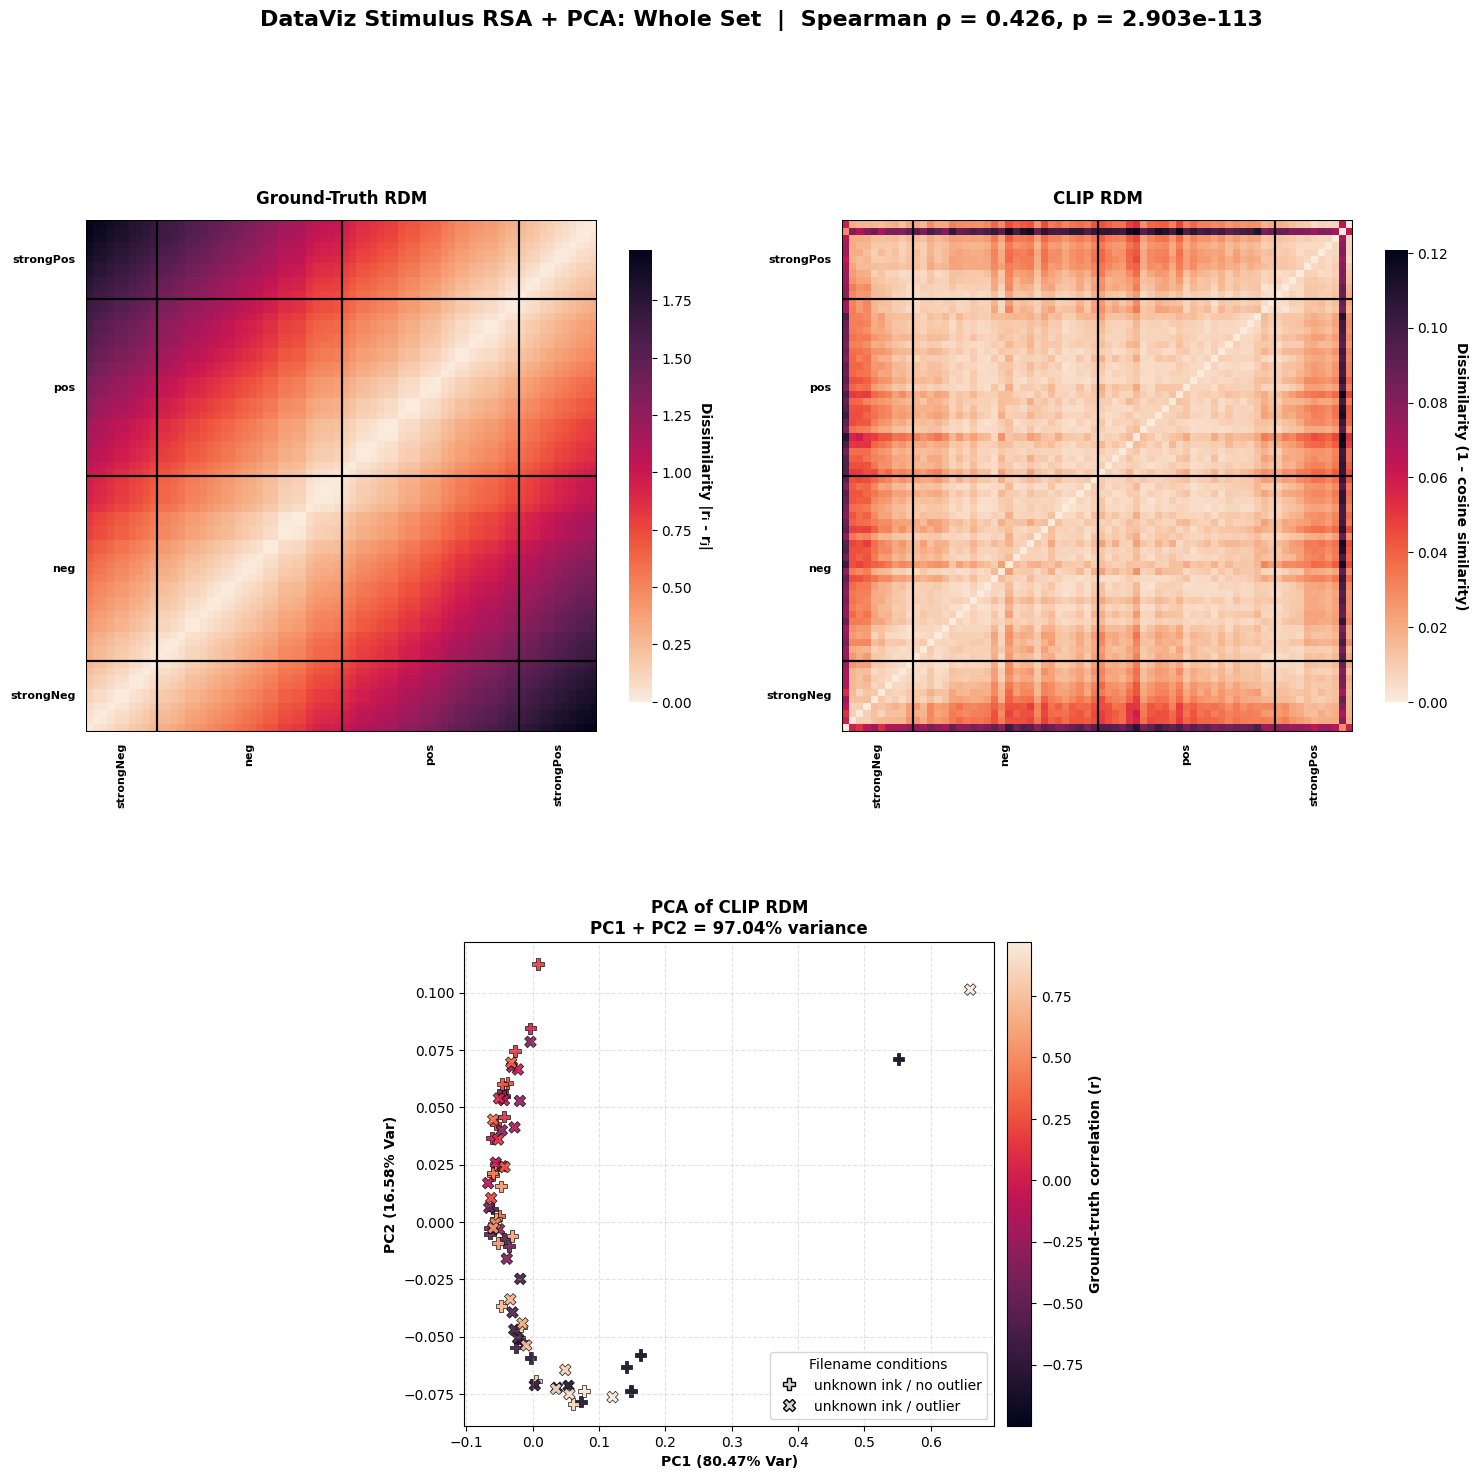


Running analysis: High Ink-On-Page Only  |  n = 0
Skipping: this subset contains no stimuli.

Running analysis: Low Ink-On-Page Only  |  n = 0
Skipping: this subset contains no stimuli.

Running analysis: No Outliers Only  |  n = 36


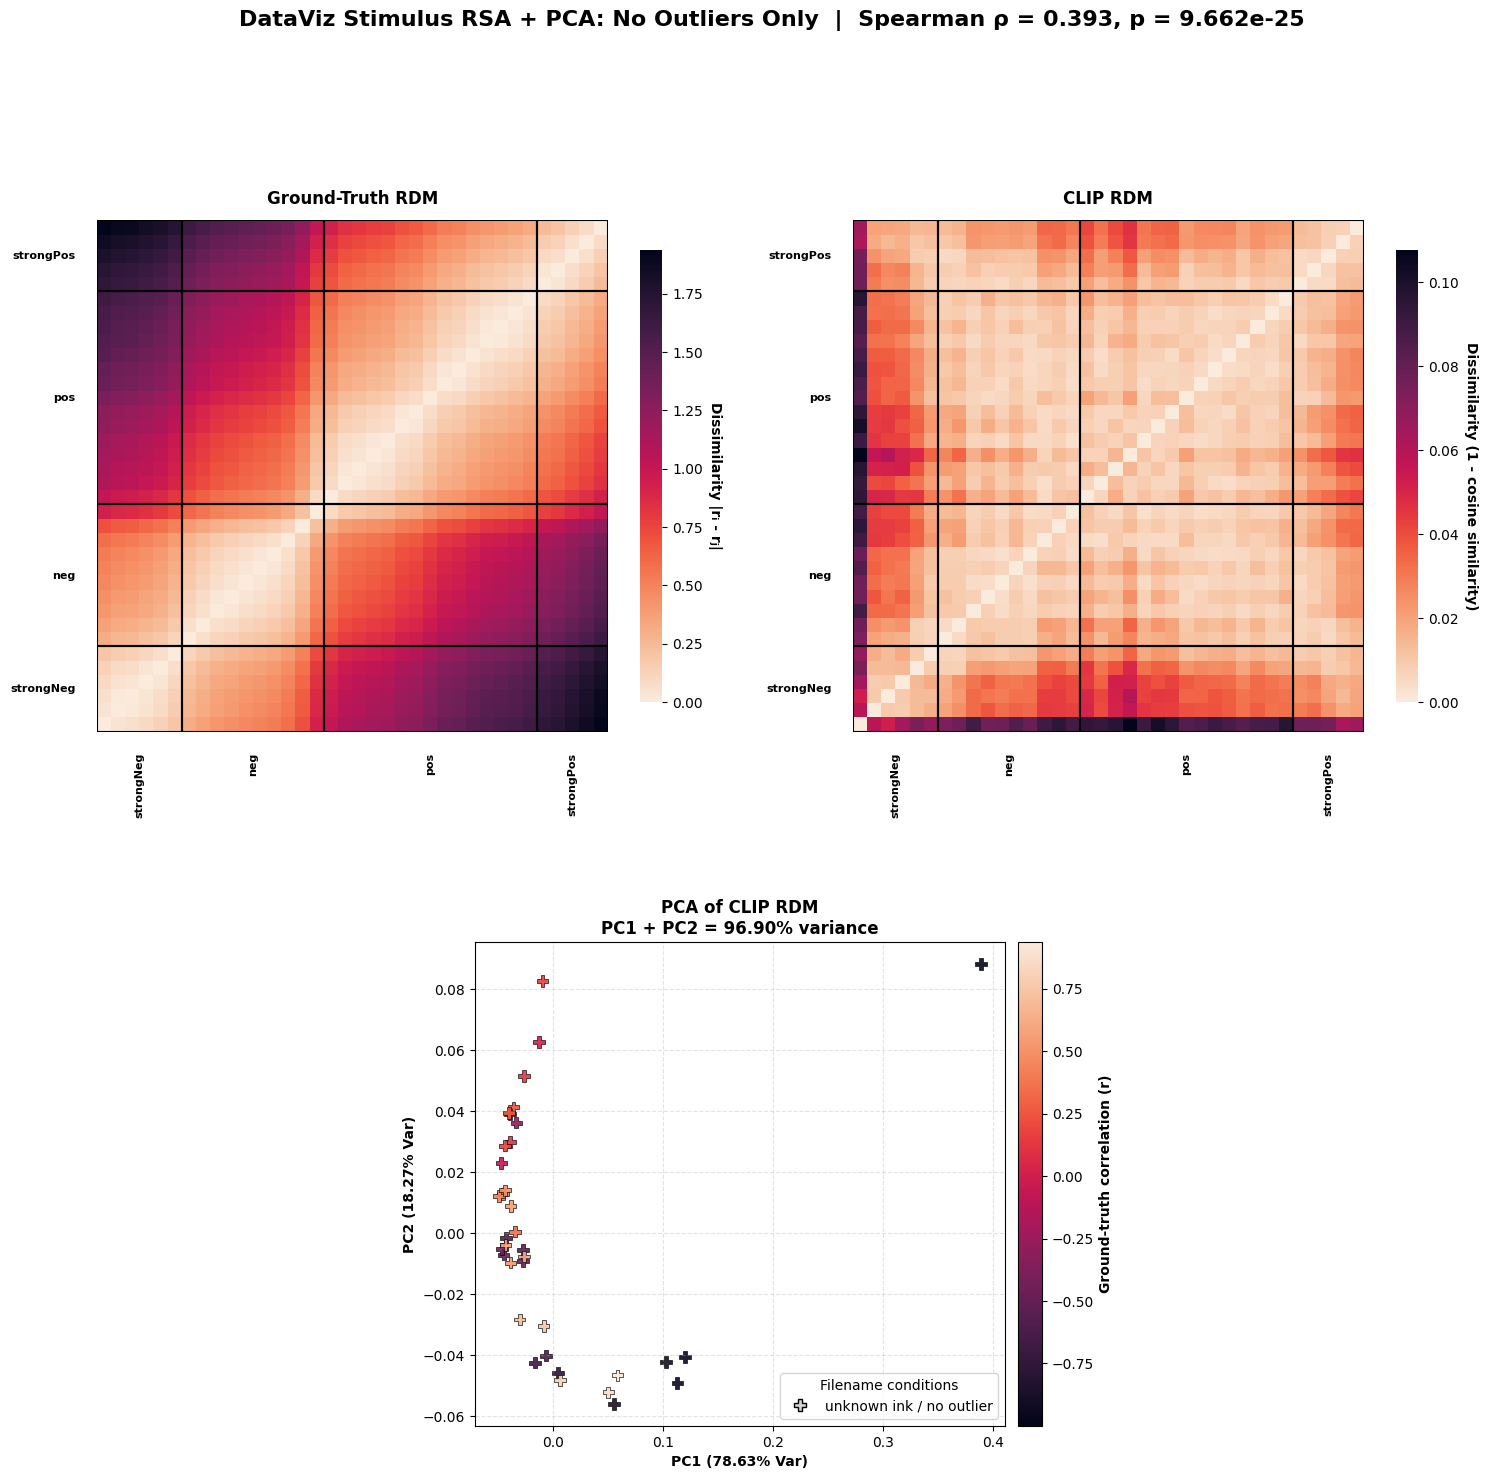


Running analysis: Outliers Only  |  n = 36


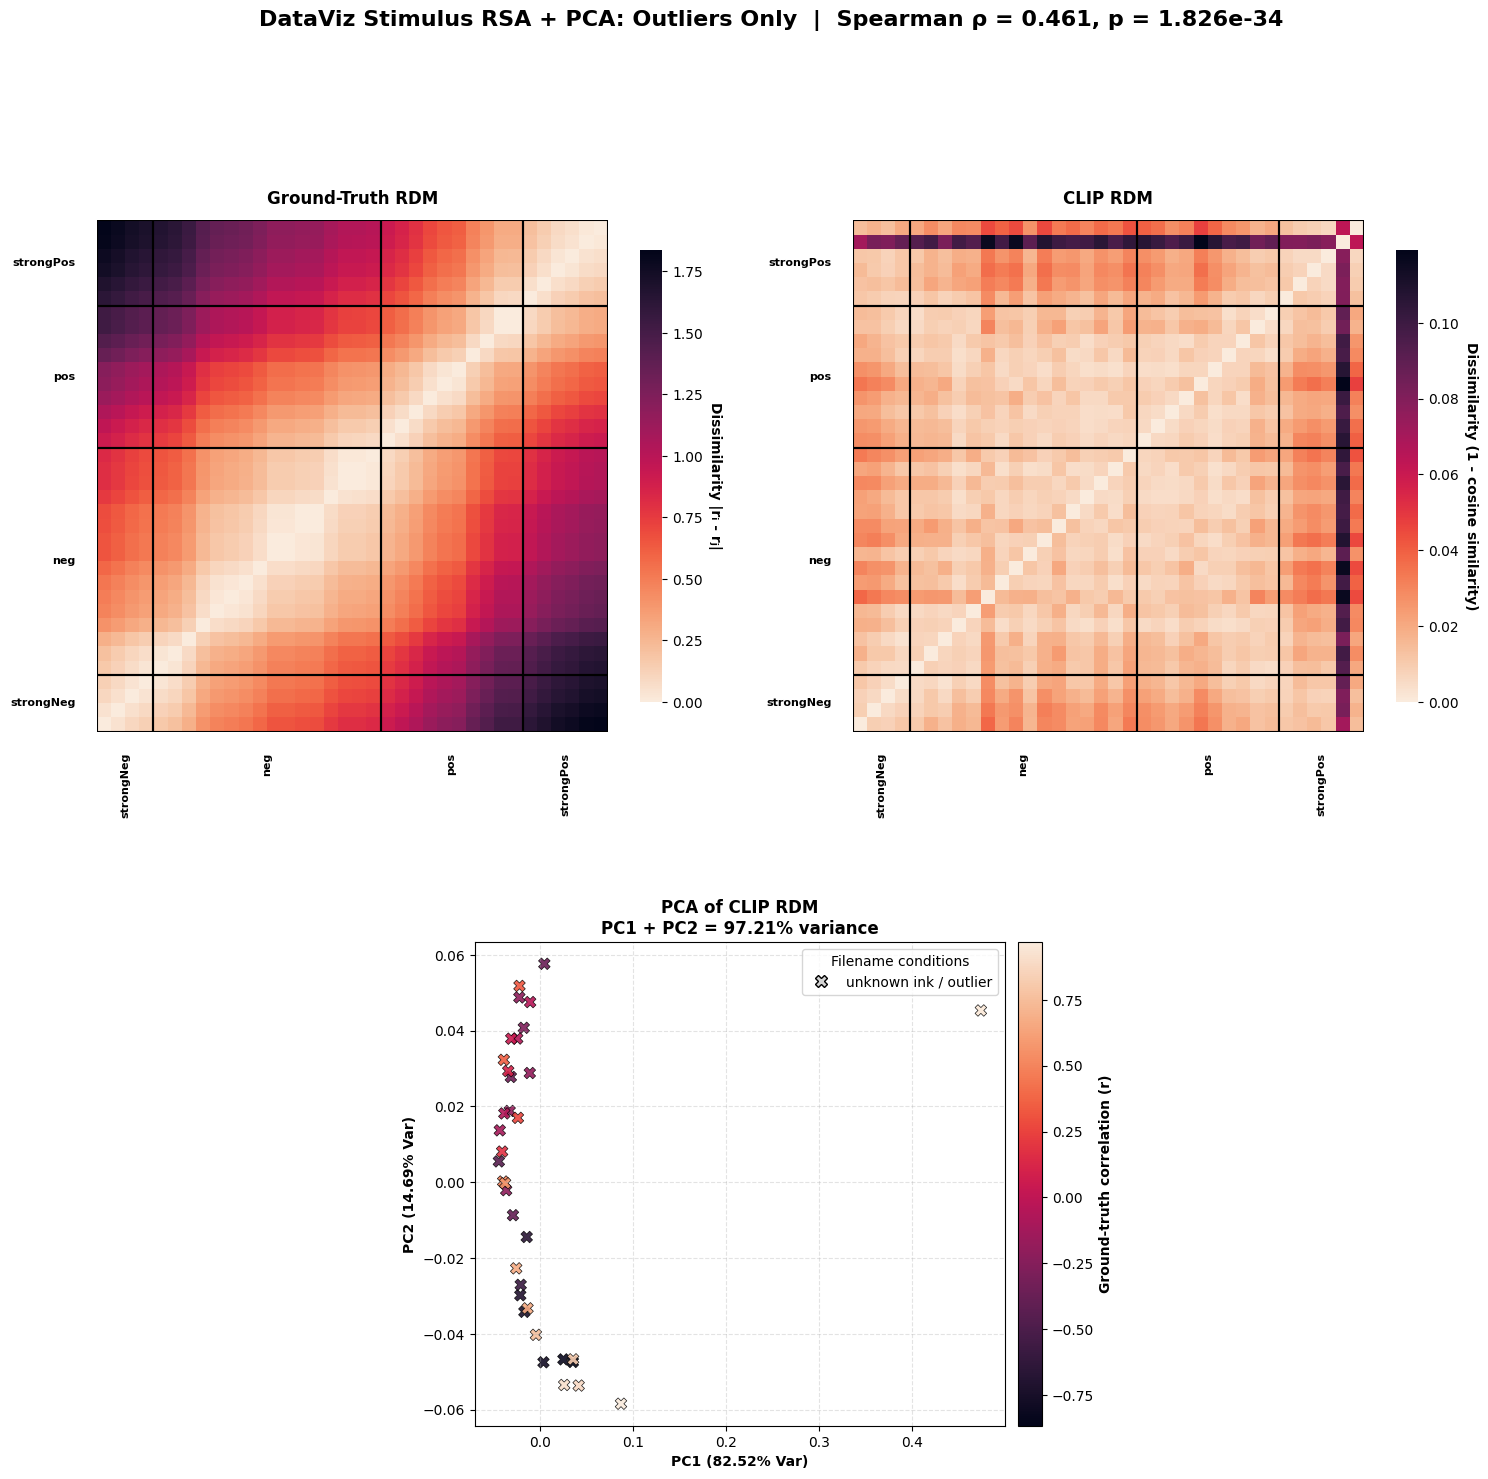


Analysis summary:


,analysis,slug,n_stimuli,rho,p_value,pc1_var,pc2_var,total_var,output_file
0,Whole Set,01_whole_set,72,0.426080,2.903282e-113,80.465088,16.577433,97.042519,DataVizStim_RSA_outputs/01_whole_set_RSA_RDM_P...
1,High Ink-On-Page Only,02_high_ink_only,0,NaN,NaN,NaN,NaN,NaN,
2,Low Ink-On-Page Only,03_low_ink_only,0,NaN,NaN,NaN,NaN,NaN,
3,No Outliers Only,04_no_outliers_only,36,0.393325,9.661971e-25,78.630066,18.274380,96.904449,DataVizStim_RSA_outputs/04_no_outliers_only_RS...
4,Outliers Only,05_outliers_only,36,0.460964,1.825801e-34,82.520905,14.685863,97.206772,DataVizStim_RSA_outputs/05_outliers_only_RSA_R...



Saved all figures and the summary CSV to: /content/DataVizStim_RSA_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
# run the following analyses:
# 1) whole set
# 2) only high ink-on-page
# 3) only low ink-on-page
# 4) only no-outlier stimuli
# 5) only outlier stimuli

output_dir = 'DataVizStim_RSA_outputs'
os.makedirs(output_dir, exist_ok=True)

analysis_specs = [
    {
        'slug': '01_whole_set',
        'title': 'Whole Set',
        'mask': pd.Series(True, index=df.index)
    },
    {
        'slug': '02_high_ink_only',
        'title': 'High Ink-On-Page Only',
        'mask': df['ink_density'].eq('high')
    },
    {
        'slug': '03_low_ink_only',
        'title': 'Low Ink-On-Page Only',
        'mask': df['ink_density'].eq('low')
    },
    {
        'slug': '04_no_outliers_only',
        'title': 'No Outliers Only',
        'mask': df['outlier'].eq(False)
    },
    {
        'slug': '05_outliers_only',
        'title': 'Outliers Only',
        'mask': df['outlier'].eq(True)
    }
]

analysis_summary = []
output_files = []

for spec in analysis_specs:
    sub_df = df.loc[spec['mask']].copy().reset_index().rename(columns={'index': 'orig_index'})
    n_subset = len(sub_df)

    print('\n' + '=' * 90)
    print(f"Running analysis: {spec['title']}  |  n = {n_subset}")
    print('=' * 90)

    if n_subset == 0:
        print('Skipping: this subset contains no stimuli.')
        analysis_summary.append({
            'analysis': spec['title'],
            'slug': spec['slug'],
            'n_stimuli': 0,
            'rho': np.nan,
            'p_value': np.nan,
            'pc1_var': np.nan,
            'pc2_var': np.nan,
            'total_var': np.nan,
            'output_file': ''
        })
        continue

    embeddings_sub = CLIP_embeddings_all[sub_df['orig_index'].to_numpy()]
    plot_df, RDM_GT, RDM_CLIP, corr_spans = prepare_sorted_subset(sub_df, embeddings_sub)
    rho, p = compute_rsa(RDM_GT, RDM_CLIP)
    pca_features, pc1_var, pc2_var, total_var = compute_pca_features(RDM_CLIP)

    output_fn = os.path.join(output_dir, f"{spec['slug']}_RSA_RDM_PCA.png")
    make_combined_figure(
        plot_df=plot_df,
        RDM_GT=RDM_GT,
        RDM_CLIP=RDM_CLIP,
        corr_spans=corr_spans,
        rho=rho,
        p=p,
        pca_features=pca_features,
        pc1_var=pc1_var,
        pc2_var=pc2_var,
        total_var=total_var,
        analysis_title=f"DataViz Stimulus RSA + PCA: {spec['title']}",
        output_fn=output_fn
    )

    output_files.append(output_fn)
    analysis_summary.append({
        'analysis': spec['title'],
        'slug': spec['slug'],
        'n_stimuli': n_subset,
        'rho': rho,
        'p_value': p,
        'pc1_var': pc1_var,
        'pc2_var': pc2_var,
        'total_var': total_var,
        'output_file': output_fn
    })

summary_df = pd.DataFrame(analysis_summary)
print('\nAnalysis summary:')
display(summary_df)

summary_csv = os.path.join(output_dir, 'RSA_analysis_summary.csv')
summary_df.to_csv(summary_csv, index=False)
output_files.append(summary_csv)

zip_base = 'DataVizStim_RSA_outputs'
zip_path = shutil.make_archive(zip_base, 'zip', output_dir)
print(f"\nSaved all figures and the summary CSV to: {zip_path}")
files.download(zip_path)


In [9]:
# save the parsed filename metadata used for this analysis
metadata_fn = "DataVizStim_Parsed_Metadata.csv"
df.to_csv(metadata_fn, index=False)
print(f"Saved parsed metadata as: {metadata_fn}")

# Uncomment if you also want the metadata file downloaded automatically:
files.download(metadata_fn)


Saved parsed metadata as: DataVizStim_Parsed_Metadata.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>